LAB 07:

Part 1: Data Acquisition and Loading 

First five rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 colum

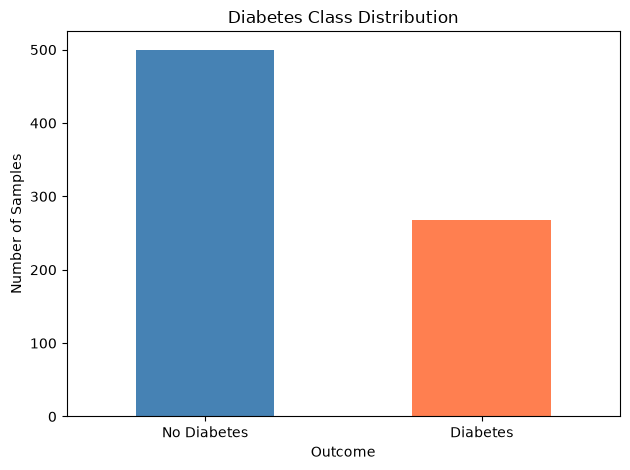

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = r"C:\Personal AI & ML PROJECTS\AI IN HEALTHCARE\diabetes.csv"

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Outcome"].value_counts().sort_index())

df["Outcome"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "coral"]
)

plt.xticks([0, 1], ["No Diabetes", "Diabetes"], rotation=0)
plt.xlabel("Outcome")
plt.ylabel("Number of Samples")
plt.title("Diabetes Class Distribution")
plt.tight_layout()
plt.show()

Task2: Data Preprocessing 

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

df = df.drop_duplicates().copy()

feature_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

required_columns = feature_columns + ["Outcome"]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

df[required_columns] = df[required_columns].apply(
    pd.to_numeric, errors="raise"
)

if df["Outcome"].isna().any():
    raise ValueError("Outcome contains missing values.")

if set(df["Outcome"].unique()) != {0, 1}:
    raise ValueError("Outcome must contain the two classes 0 and 1.")

zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

X = df[feature_columns].astype("float32")
y = df["Outcome"].astype("int32")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Missing values after replacing invalid zeros:")
print(X.isnull().sum())

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

Training features: (614, 8)
Testing features: (154, 8)

Training class proportions:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing class proportions:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


Task3: Deep Learning Grid Search 


Tuning: Batch Size and Epochs
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Results for every candidate:
                                    params  mean_test_score  std_test_score
{'ann__batch_size': 32, 'ann__epochs': 60}         0.775235        0.010723
{'ann__batch_size': 32, 'ann__epochs': 30}         0.775219        0.017696
{'ann__batch_size': 16, 'ann__epochs': 60}         0.773625        0.012630
{'ann__batch_size': 16, 'ann__epochs': 30}         0.773617        0.009977

Selected parameters: {'ann__batch_size': 32, 'ann__epochs': 60}
Best CV accuracy: 0.7752

Tuning: Learning Rate
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Results for every candidate:
                               params  mean_test_score  std_test_score
 {'ann__model__learning_rate': 0.001}         0.775235        0.010723
  {'ann__model__learning_rate': 0.01}         0.745903        0.011147
{'ann__model__learning_rate': 0.0001}         0.672692        0.025494

Selected par

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,317 (12.96 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,212 (8.64 KB)


TEST SET PERFORMANCE
Accuracy     0.7143
Precision    0.5962
Recall       0.5741
F1 Score     0.5849
ROC-AUC      0.8130
dtype: float64

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.77      0.79      0.78       100
    Diabetes       0.60      0.57      0.58        54

    accuracy                           0.71       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.71      0.71       154


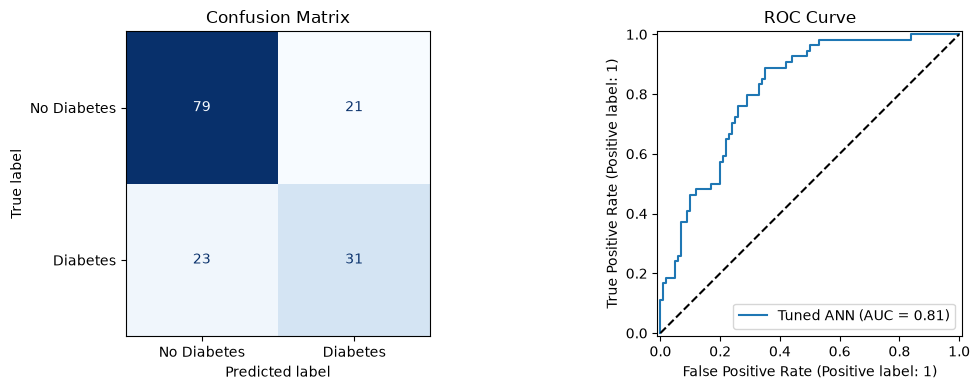

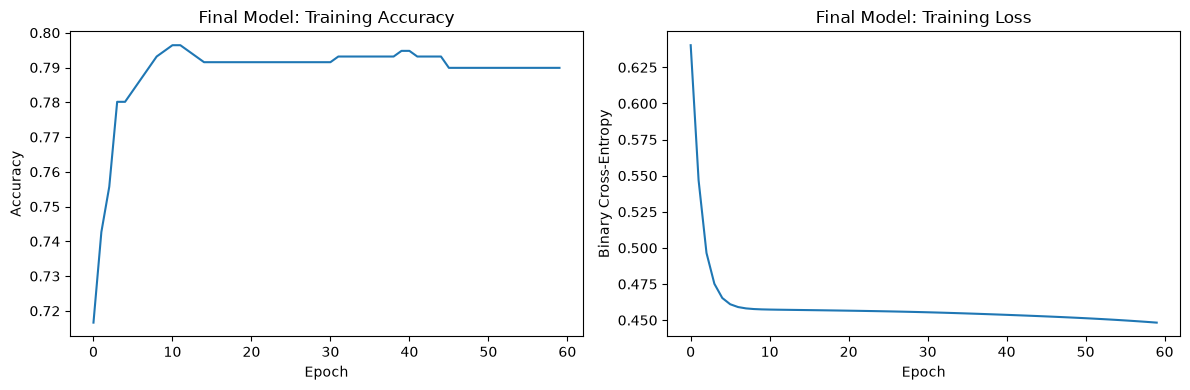

In [4]:
import keras

from keras import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam

from scikeras.wrappers import KerasClassifier

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

keras.utils.set_random_seed(42)


# 1. Define the neural network
def create_model(
    meta,
    neurons=32,
    activation="relu",
    weight_init="glorot_uniform",
    dropout_rate=0.2,
    learning_rate=0.001
):
    keras.backend.clear_session()

    model = Sequential([
        Input(shape=(meta["n_features_in_"],)),

        Dense(
            neurons,
            activation=activation,
            kernel_initializer=weight_init
        ),
        Dropout(dropout_rate),

        Dense(
            8,
            activation=activation,
            kernel_initializer=weight_init
        ),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 2. Connect Keras to scikit-learn
classifier = KerasClassifier(
    model=create_model,
    model__neurons=32,
    model__activation="relu",
    model__weight_init="glorot_uniform",
    model__dropout_rate=0.2,
    model__learning_rate=0.001,
    batch_size=32,
    epochs=30,
    verbose=0,
    random_state=42
)


# 3. Keep preprocessing inside cross-validation
pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("ann", classifier)
])

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


# 4. Define all six grid searches
search_stages = [
    (
        "Batch Size and Epochs",
        {
            "ann__batch_size": [16, 32],
            "ann__epochs": [30, 60]
        }
    ),
    (
        "Learning Rate",
        {
            "ann__model__learning_rate": [0.0001, 0.001, 0.01]
        }
    ),
    (
        "Weight Initialization",
        {
            "ann__model__weight_init": [
                "glorot_uniform",
                "he_normal",
                "random_normal"
            ]
        }
    ),
    (
        "Activation Function",
        {
            "ann__model__activation": ["relu", "tanh", "sigmoid"]
        }
    ),
    (
        "Dropout Regularization",
        {
            "ann__model__dropout_rate": [0.0, 0.2, 0.4]
        }
    ),
    (
        "Number of Neurons",
        {
            "ann__model__neurons": [16, 32, 64]
        }
    )
]


# 5. Run searches and retain the selected settings
selected_parameters = {}
stage_results = []

for stage_name, parameter_grid in search_stages:
    print(f"\n{'=' * 60}")
    print(f"Tuning: {stage_name}")
    print("=" * 60)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=1,
        refit=False,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    results = pd.DataFrame(search.cv_results_)

    print("\nResults for every candidate:")
    print(
        results[
            ["params", "mean_test_score", "std_test_score"]
        ]
        .sort_values("mean_test_score", ascending=False)
        .to_string(index=False)
    )

    print("\nSelected parameters:", search.best_params_)
    print(f"Best CV accuracy: {search.best_score_:.4f}")

    selected_parameters.update(search.best_params_)
    pipeline.set_params(**search.best_params_)

    stage_results.append({
        "Stage": stage_name,
        "Best CV Accuracy": search.best_score_,
        "Selected Parameters": search.best_params_
    })


# 6. Display the tuning summary
print("\nTUNING SUMMARY")
print(pd.DataFrame(stage_results).to_string(index=False))

print("\nFINAL SELECTED PARAMETERS")
for name, value in selected_parameters.items():
    print(f"{name.replace('ann__', '')}: {value}")


# 7. Train the selected configuration on all training data
best_model = clone(pipeline)
best_model.fit(X_train, y_train)

print("\nFINAL NEURAL NETWORK")
best_model.named_steps["ann"].model_.summary()


# 8. Evaluate once on the held-out test set
y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
})

print("\nTEST SET PERFORMANCE")
print(test_metrics.round(4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)


# 9. Plot the confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    ax=axes[1],
    name="Tuned ANN"
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()


# 10. Plot training history for the final model
history = best_model.named_steps["ann"].history_

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["accuracy"])
axes[0].set_title("Final Model: Training Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(history["loss"])
axes[1].set_title("Final Model: Training Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")

plt.tight_layout()
plt.show()